# Полиномиальная регрессия



## Обо мне

🐍 **Эксперт по Python и Data Science**. В 2020 году ушёл из найма, сейчас реализую собственные проекты, занимаюсь IT-образованием и консультированием.

👨‍💻 **Опыт в образовании**. В IT-образовании с 2016 года. За это время провел более 3000 лекций и вебинаров, обучил тысячи студентов, многие из которых сейчас работают в ведущих IT-компаниях. Создаю авторские курсы, консультирую крупные компании по вопросам Data Science и участвую в разработке образовательных программ для университетов и онлайн-школ.

🎯 Стремлюсь сделать обучение качественным и честным для всех, кто хочет развиваться в IT-сфере.

📱 Делюсь полезными материалами в своём [Telegram-канале об IT и AI](https://t.me/oleg_payload).

In [ ]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import r2_score
!pip install phik
import phik
from phik.report import plot_correlation_matrix

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 8.0 MB/s  0:00:00



Полиномиальная регрессия (Polynomial Regression) — это более сложная модель, чем линейная регрессия. Вместо уравнения прямой используется уравнение полинома (многочлена), который отражает нелинейную зависимость. Степень полинома может быть сколь угодно большой: чем больше степень, тем сложнее модель.

В простом двумерном случае, когда мы рассматриваем зависимость целевого признака от одного фактора, полиномом второй степени будет уравнение параболы:

$$y = k_1 x + k_2 x^2 + b$$



Геометрически полином в двумерном пространстве — это некоторая кривая, которая пытается описать зависимость в данных. Выглядит это следующим образом:



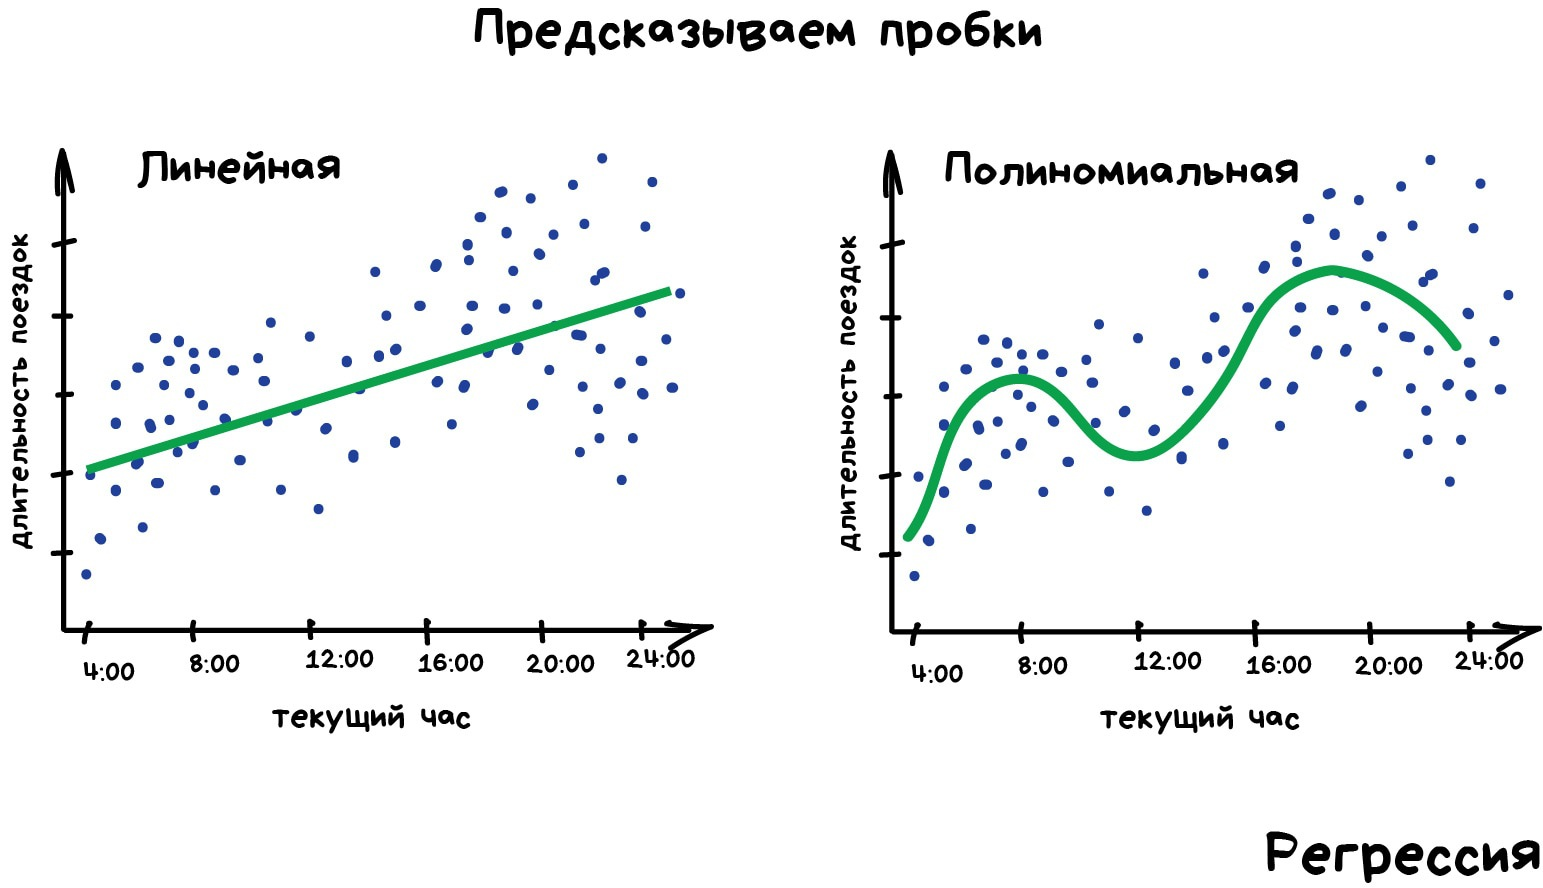

Когда факторов больше одного, например два, то, помимо возведения фактора в квадрат, появляются ещё и комбинации из x1 и x2:


$$\hat{y}=k_{1} x_{1}+k_{2} x_{1}^{2}+k_{3} x_{2}+k_{4} x^{2}_{2}+k_{5} x_{1} x_{2} + b$$


Такая модель описывает сложную поверхность в трёхмерном пространстве, которая проставлена на рисунке:




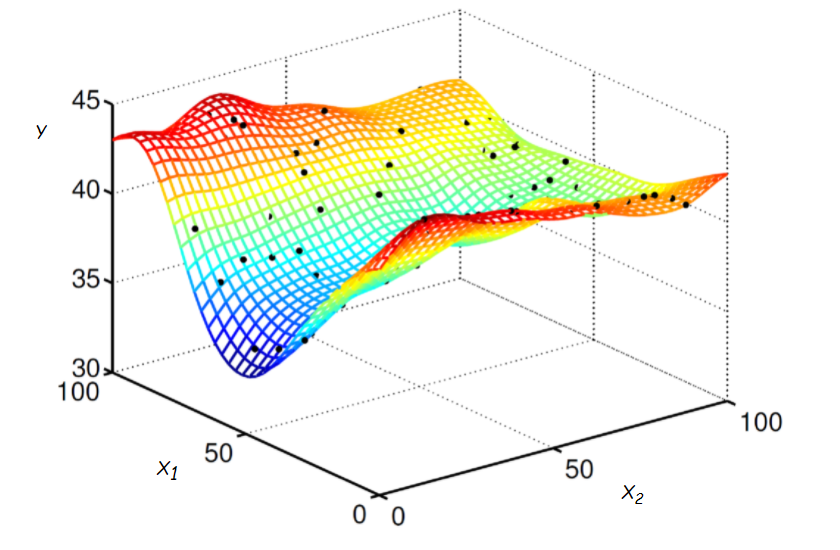

Количество коэффициентов очень быстро растёт при увеличинении количества факторов, а с ним и сложность модели.






Степени  можно тоже считать своего рода искусственными признаками в данных. Они называются полиномиальными признаками.

Поэтому полиномиальная регрессия — это та же линейная регрессия, просто с новыми признаками. Полиномиальные признаки — один из самых распространённых методов FeatureEngineering.


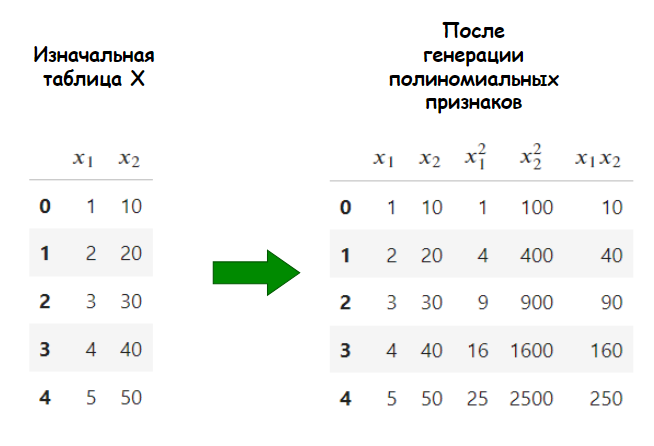

Благодаря степенным слагаемым модель становится сложнее и начинает улавливать более сложные зависимости и выдавать меньшее смещение.

Чтобы построить полиномиальную регрессиию в sklearn необходимо создать полиномиальные признаки с помощью объекта класса [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) из модуля preprocessing. Это преобразователь, который позволит сгенерировать полиномиальные признаки любой степени и добавить их в таблицу. У класса есть 2 основных параметра:

- `degree` — степень полинома. По умолчанию используется степень 2.
- `include_bias` — включать ли в результирующую таблицу столбец из единиц (x в степени 0), который соответствует свободному члену в модели. По умолчанию стоит `True`, но лучше выставить его в значение `False`,т.к. линейные модели в sklearn по умолчанию подразумевают смещение (intercept).



В реальной практике, как правило используется полином второй (максимум третьей) степени. Чем выше степень полинома, тем больше слагаемых, а значит, тем больше признаков и тем сложнее становится модель.





In [ ]:
from sklearn.datasets import fetch_openml

data = fetch_openml(name='house_sales')
print(data.DESCR)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name house_sales exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=42079
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=42092

  warn(warning_msg)


**Author**: https://www.kaggle.com/harlfoxem/  
https://www.kaggle.com/harlfoxem/  
**Source**: [original](https://www.kaggle.com/harlfoxem/housesalesprediction) - 2016-08-25  
**Please cite**:   

This dataset contains house sale prices for King County, which includes Seattle. It includes homes sold between May 2014 and May 2015.

It contains 19 house features plus the price and the id columns, along with 21613 observations.
It's a great dataset for evaluating simple regression models.

* Id: Unique ID for each home sold
* Date: Date of the home sale
* Price: Price of each home sold
* Bedrooms: Number of bedrooms
* Bathrooms: Number of bathrooms, where .5 accounts for a room with a toilet but no shower
* Sqft_living: Square footage of the apartments interior living space
* Sqft_lot: Square footage of the land space
* Floors: Number of floors
* Waterfront: A dummy variable for whether the apartment was overlooking the waterfront or not
* View: An index from 0 to 4 of how good the view 

In [ ]:
df = data.data
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [ ]:
df[df['yr_renovated'] != 0]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
1,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
35,20140613T000000,696000.0,3,2.50,2300,3060,1.5,0,0,3,8,1510,790,1930,2002,98115,47.6827,-122.310,1590,3264
95,20140908T000000,905000.0,4,2.50,3300,10250,1.0,0,0,3,7,2390,910,1946,1991,98040,47.5873,-122.249,1950,6045
103,20141007T000000,1088000.0,3,2.50,2920,8113,2.0,0,0,3,8,2920,0,1950,2010,98004,47.5814,-122.196,2370,8113
115,20141121T000000,740500.0,3,3.50,4380,6350,2.0,0,0,3,8,2780,1600,1900,1999,98117,47.6981,-122.368,1830,6350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19622,20150114T000000,1150000.0,3,1.75,1760,6788,2.0,1,4,3,7,1760,0,1940,1960,98125,47.7336,-122.284,1630,7588
20057,20140904T000000,434900.0,3,2.00,1520,5040,2.0,0,0,3,7,1520,0,1977,2006,98177,47.7770,-122.362,1860,8710
20444,20150225T000000,500012.0,4,2.50,2400,9612,1.0,0,0,3,8,1230,1170,1962,2009,98059,47.4799,-122.127,2430,5539
20447,20150212T000000,356999.0,3,1.50,1010,1546,2.0,0,0,3,8,1010,0,1971,2014,98144,47.5998,-122.311,1010,1517


In [ ]:
df = data.data.drop(['date', 'zipcode', 'lat', 'long', 'yr_renovated'], axis=1)
X_train, X_test, y_train, y_test = train_test_split(df.drop('price', axis=1),
                                                    df['price'],
                                                    random_state=42)

Для начала создадим обычную модель без полиномиальных признаков, чтобы сравнивать качество с ней.



In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)




In [ ]:
lm = LinearRegression()


lm.fit(X_train_scaled, y_train)
y_pred_scaled = lm.predict(X_test_scaled)
y_pred_scaled

from sklearn.metrics import r2_score

print(f'R2: {r2_score(y_test, y_pred_scaled)}')

R2: 0.6591471618009244


При реализации полиномиальной регрессии стоит проводить масштабирование **перед** генерацией полиномиальных признаков.

Это улучшает качество модели и обеспечивает более стабильные результаты при обучении.

Если делать масштабирование после создания полиномов, то:

- значения новых признаков могут значительно варьироваться. Стандартизация этих полиномов может сделать интерпретацию коэффициентов модели более сложной, так как значения полиномов уже изменены и не соответствуют исходным данным. Это затрудняет понимание того, как каждый признак влияет на зависимую переменную.

- модель станет более чувствительной к выбросам и шуму в данных. Поскольку полиномиальные признаки могут иметь большие значения, их стандартизация может не устранить проблемы переобучения, а наоборот, усугубить их, так как модель будет пытаться подстроиться под измененные масштабы.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures


poly = PolynomialFeatures(degree=2, include_bias=False)

# fit_transform на трейне — обучаем преобразователь И применяем
X_train_poly = poly.fit_transform(X_train_scaled)
# transform на тесте — ТОЛЬКО применяем (важно: без fit!)
X_test_poly = poly.transform(X_test_scaled)

# 3. Посмотрим, как выглядят тренировочные данные после преобразования
poly_feature_names = poly.get_feature_names_out(input_features=X_train.columns)

X_train_poly_df = pd.DataFrame(X_train_poly, columns=poly_feature_names)
X_train_poly_df.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,...,sqft_basement^2,sqft_basement yr_built,sqft_basement sqft_living15,sqft_basement sqft_lot15,yr_built^2,yr_built sqft_living15,yr_built sqft_lot15,sqft_living15^2,sqft_living15 sqft_lot15,sqft_lot15^2
0,0.677402,0.178963,-0.290276,-0.144952,0.922943,-0.083788,-0.306964,-0.626000,-0.557611,0.030720,...,0.432757,0.227392,0.311759,0.085382,0.119483,0.163814,0.044864,0.224591,0.061509,0.016846
1,-0.394132,0.505667,-0.521813,-0.311135,0.922943,-0.083788,-0.306964,0.908842,-0.557611,-0.224818,...,0.432757,-0.466918,0.253874,0.223021,0.503775,-0.273914,-0.240626,0.148934,0.130834,0.114934
2,0.677402,0.505667,-0.389506,-0.160457,0.922943,-0.083788,-0.306964,-0.626000,0.296350,-0.078796,...,0.432757,-0.511712,0.109163,0.128982,0.605072,-0.129079,-0.152514,0.027536,0.032536,0.038443
3,-1.465666,0.178963,-0.918734,-0.364787,0.922943,-0.083788,-0.306964,-0.626000,-0.557611,-0.772399,...,0.204881,-0.583250,0.493308,0.201435,1.660381,-1.404336,-0.573441,1.187776,0.485012,0.198048
4,-0.394132,-0.147741,-0.874632,-0.038936,-0.918626,-0.083788,-0.306964,-0.626000,-0.557611,-0.614209,...,0.432757,-0.511712,0.379291,0.113936,0.605072,-0.448491,-0.134723,0.332430,0.099859,0.029997


In [ ]:
lm_poly = LinearRegression()
lm_poly.fit(X_train_poly, y_train)

y_train_pred_poly = lm_poly.predict(X_train_poly)
y_test_pred_poly = lm_poly.predict(X_test_poly)

print(f'R2 на тренировочной выборке: {r2_score(y_train, y_train_pred_poly):.4f}')
print(f'R2 на тестовой выборке:      {r2_score(y_test, y_test_pred_poly):.4f}')


print(f'\nДля сравнения — обычная линейная регрессия:')
print(f'R2 на тренировочной выборке: {r2_score(y_train, lm.predict(X_train_scaled)):.4f}')
print(f'R2 на тестовой выборке:      {r2_score(y_test, y_pred_scaled):.4f}')


R2 на тренировочной выборке: 0.7511
R2 на тестовой выборке:      0.7067

Для сравнения — обычная линейная регрессия:
R2 на тренировочной выборке: 0.6512
R2 на тестовой выборке:      0.6591


# Переобучение и недообучение
______________________________________________
Обсудим две очень важные проблемы обучения всех моделей ML.

Эти общие проблемы называются **переобучением** и **недообучением**. Их названия достаточно полно описывают их суть, но мы подробно разберёмся в причинах их возникновения.



## Недообучение
Недообучение - это случай, когда модель по тем или иным причинам не смогла обобщить закономерности в данных и выучить необходимые зависимости.



Сгенерируем случайные данные с нелинейной зависимостью, которые можно описать полиномом 3 степени:

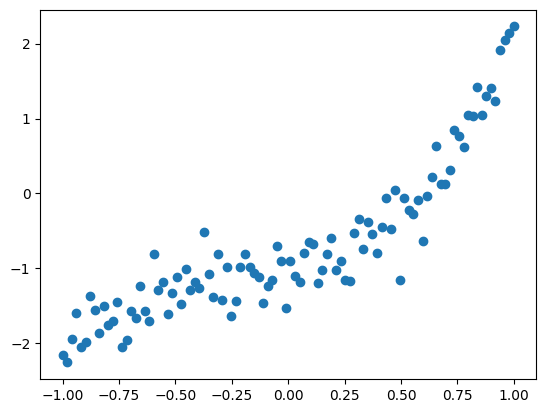

In [ ]:
np.random.seed(42)
x_data = np.linspace(-1, 1, 100)
y_data = np.polyval([2, 1, 0.3, -1], x_data) + np.random.randn(x_data.shape[0]) * 0.3 # добавим шум

plt.scatter(x_data, y_data)

В данном случае требуется смоделировать поведение полинома 3 степени. Что получится, если мы попробуем построить линейную регрессию?

In [ ]:
# Преобразование данных для регрессии
x_data_reshaped = x_data.reshape(-1, 1)
x_data_reshaped

array([[-1.        ],
       [-0.97979798],
       [-0.95959596],
       [-0.93939394],
       [-0.91919192],
       [-0.8989899 ],
       [-0.87878788],
       [-0.85858586],
       [-0.83838384],
       [-0.81818182],
       [-0.7979798 ],
       [-0.77777778],
       [-0.75757576],
       [-0.73737374],
       [-0.71717172],
       [-0.6969697 ],
       [-0.67676768],
       [-0.65656566],
       [-0.63636364],
       [-0.61616162],
       [-0.5959596 ],
       [-0.57575758],
       [-0.55555556],
       [-0.53535354],
       [-0.51515152],
       [-0.49494949],
       [-0.47474747],
       [-0.45454545],
       [-0.43434343],
       [-0.41414141],
       [-0.39393939],
       [-0.37373737],
       [-0.35353535],
       [-0.33333333],
       [-0.31313131],
       [-0.29292929],
       [-0.27272727],
       [-0.25252525],
       [-0.23232323],
       [-0.21212121],
       [-0.19191919],
       [-0.17171717],
       [-0.15151515],
       [-0.13131313],
       [-0.11111111],
       [-0

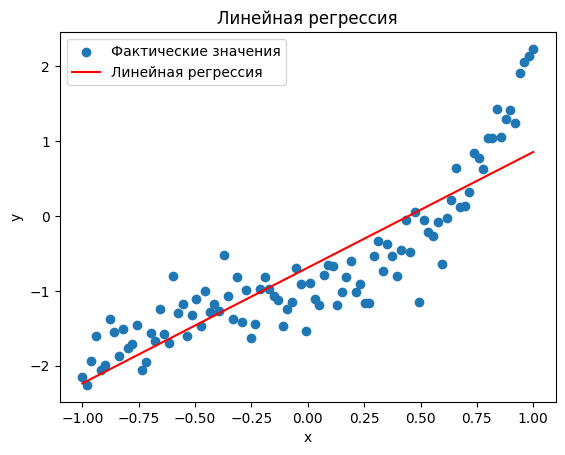

In [ ]:
linear_model = LinearRegression()
linear_model.fit(x_data_reshaped, y_data)

# Предсказания линейной регрессии
y_pred_linear = linear_model.predict(x_data_reshaped)

# Визуализация линейной регрессии
plt.scatter(x_data, y_data, label='Фактические значения')
plt.plot(x_data, y_pred_linear, color='red', label='Линейная регрессия')
plt.title('Линейная регрессия')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

Очевидно, что линейная регрессия с этой задачей не справляется. Всё дело в том, что этой модели банально не хватает параметров для того, чтобы смоделировать слишком сложную зависимость. Это один из возможных примеров ситуации **недообучения**.

Решение проблемы недообучения обычно довольно простое. Достаточно выбрать более сложные модели с большим числом параметров.

Если в приведенном примере мы увеличим число параметров модели, заменив линейную регрессию полиномиальной регрессией третьей степени, мы без труда решим поставленную задачу с достаточно высокой точностью.

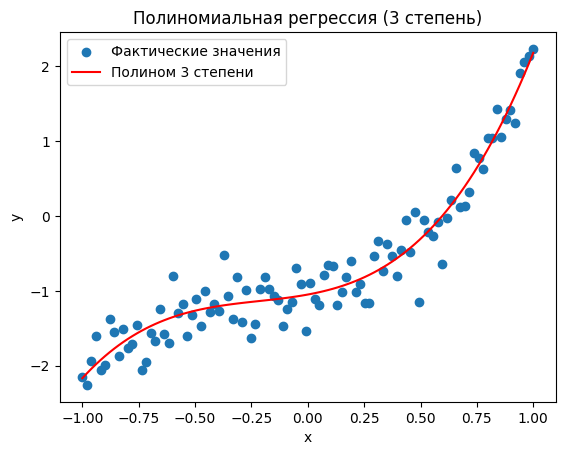

In [ ]:
poly_features_3 = PolynomialFeatures(degree=3, include_bias=False)
X_poly_3 = poly_features_3.fit_transform(x_data_reshaped)

poly_model_3 = LinearRegression()
poly_model_3.fit(X_poly_3, y_data)
y_pred_poly_3 = poly_model_3.predict(X_poly_3)

plt.scatter(x_data, y_data, label='Фактические значения')
plt.plot(x_data, y_pred_poly_3, color='red', label='Полином 3 степени')
plt.title('Полиномиальная регрессия (3 степень)')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## Переобучение

Проблема переобучения более сложная и комплексная, чем проблема недообучения.

Если недообучение связано с недостаточной сложностью выбранной модели, то переобучение следует из **избыточной сложности**. Вопреки ожиданиям, слишком сложная модель также неспособна выучить нужные зависимости в данных. Но она с высокой вероятностью выучит зависимости в данных, которые там появились по чистой случайности и не являются естественными для нашей задачи.

Другой распространённой причиной проблемы переобучения является **недостаток данных**. На самом деле, недостаток данных в некоторых случаях может быть скомпенсиррован уменьшением сложности модели. А желание усложнить модель всегда приводит нас к необходимости увеличить и набор данных, которые мы используем для обучения.




Ранее мы смоделировали многочлен третьей степени слишком простой моделью, то есть линейной регрессией. Она плохо справилась с задачей. Очевидно, что и полином второй степени вряд ли справится с этой задачей хорошо, ведь исходные данные смоделированны при помощи полиномиальной зависимости третьей степени.

А что если взять полином 4 степени в качестве модели? А 5? Может быть, 30 степени? Ведь каждый из них может моделировать и зависимости меньших порядков, то есть в теории полином 30 степени должен также хорошо справиться с задачей, как и полинном 3 степени, а может даже лучше.

Проверим, так ли это:

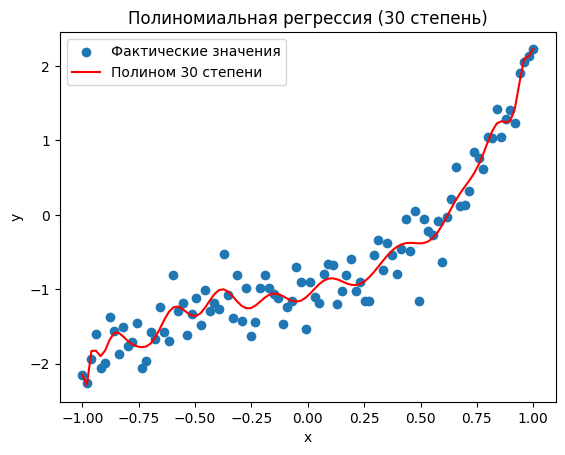

In [ ]:
poly_features_30 = PolynomialFeatures(degree=30, include_bias=False)
X_poly_30 = poly_features_30.fit_transform(x_data_reshaped)

poly_model_30 = LinearRegression()
poly_model_30.fit(X_poly_30, y_data)
y_pred_poly_30 = poly_model_30.predict(X_poly_30)

plt.scatter(x_data, y_data, label='Фактические значения')
plt.plot(x_data, y_pred_poly_30, color='red', label='Полином 30 степени')
plt.title('Полиномиальная регрессия (30 степень)')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

А теперь проверим качество всех вариантов.

Сначала на трейне:

In [ ]:
r2_linear_train  = r2_score(y_data, y_pred_linear)
r2_poly_3_train  = r2_score(y_data, y_pred_poly_3)
r2_poly_30_train = r2_score(y_data, y_pred_poly_30)

print(f'Линейная модель,               R^2 (train): {r2_linear_train:.4f}')
print(f'Полиномиальная модель (3 ст.),  R^2 (train): {r2_poly_3_train:.4f}')
print(f'Полиномиальная модель (30 ст.), R^2 (train): {r2_poly_30_train:.4f}')

Линейная модель,               R^2 (train): 0.7748
Полиномиальная модель (3 ст.),  R^2 (train): 0.9336
Полиномиальная модель (30 ст.), R^2 (train): 0.9453


А теперь на тесте

In [ ]:
# Генерация тестовых данных
x_data_test = np.linspace(-1, 1, 100)  # Используем тот же диапазон
y_data_test = np.polyval([2, 1, 0.3, -1], x_data_test) + np.random.randn(x_data_test.shape[0]) * 0.3

x_test_reshaped = x_data_test.reshape(-1, 1)


In [ ]:
# --- Линейная модель: просто predict ---
preds_linear = linear_model.predict(x_test_reshaped)

# --- Полином 3-й степени: сначала transform (НЕ fit_transform!), затем predict ---
X_test_poly_3 = poly_features_3.transform(x_test_reshaped)
preds_poly_3  = poly_model_3.predict(X_test_poly_3)

# --- Полином 30-й степени: то же самое ---
X_test_poly_30 = poly_features_30.transform(x_test_reshaped)
preds_poly_30  = poly_model_30.predict(X_test_poly_30)

r2_linear_test  = r2_score(y_data_test, preds_linear)
r2_poly_3_test  = r2_score(y_data_test, preds_poly_3)
r2_poly_30_test = r2_score(y_data_test, preds_poly_30)


print(f'\nЛинейная модель,               R^2 (test): {r2_linear_test:.4f}')
print(f'Полиномиальная модель (3 ст.),  R^2 (test): {r2_poly_3_test:.4f}')
print(f'Полиномиальная модель (30 ст.), R^2 (test): {r2_poly_30_test:.4f}')


Линейная модель,               R^2 (test): 0.7662
Полиномиальная модель (3 ст.),  R^2 (test): 0.9181
Полиномиальная модель (30 ст.), R^2 (test): 0.8975


Посмотрим визуализацию всего прогнозов на тесте:

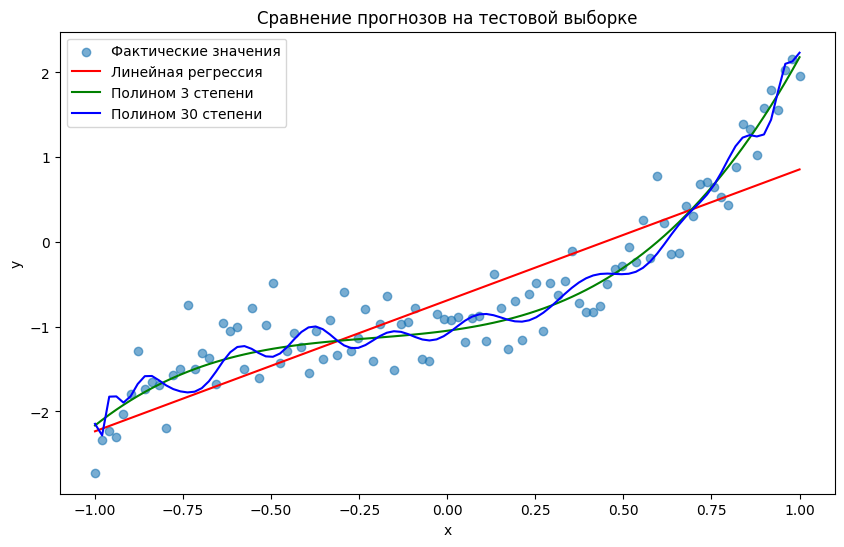

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(x_data_test, y_data_test, label='Фактические значения', alpha=0.6)
plt.plot(x_data_test, preds_linear,  color='red',   label='Линейная регрессия')
plt.plot(x_data_test, preds_poly_3,  color='green', label='Полином 3 степени')
plt.plot(x_data_test, preds_poly_30, color='blue',  label='Полином 30 степени')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Сравнение прогнозов на тестовой выборке')
plt.show()

Очевидно, полином 3 степени проявляет себя существенно лучше.

При этом обратим внимание: ошибка полинома 30 степени на тренировочной выборке самая низкая. А вот на тестовой выборке его результат уже сильно хуже результата на тестовой выборке.
В этом и состоит переобучение - модель очень хорошо подстраивается под тренировочный набор данных, но не даёт качественных результатов в реальных условиях.

Поэтому использование тестовой выборки - один из основных способов отслеживания переобучения.

В идеале мы хотим построить модель, которая точно описывает зависимости в тренировочных данных и хорошо работает на неизвестных данных. К сожалению, обычно это невозможно идеально сделать одновременно.

# Регуляризация

Одно из основных допущений модели множественной  регрессии состоит в том, что не должно быть (а если есть, то очень слабая) **мультиколлинеарности** между признаками. По сути, это означает, что признаки в идеале не должны иметь никакой корреляции друг с другом, разве что очень слабую.  
Высокая корреляция между двумя признаками порождает несколько проблем. Если мы включим один из них в модель, добавление другого практически не повлияет на улучшение модели, а только усложнит ее.
Это противоречит принципу "бережливости" при построении моделей, который диктует, что более простая модель с меньшим количеством переменных при прочих равных предпочтительнее более сложной модели со слишком большим количеством признаков.
А в такой ситуации вся модель регрессии становится менее надёжной, поскольку оценки коэффициентов имеют высокую дисперсию, то есть они плохо обобщают новые данные и возникает проблема переобучения.

Давайте посмотрим на корреляцию между признаками по нашим данным:

interval columns not set, guessing: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'sqft_living15', 'sqft_lot15']


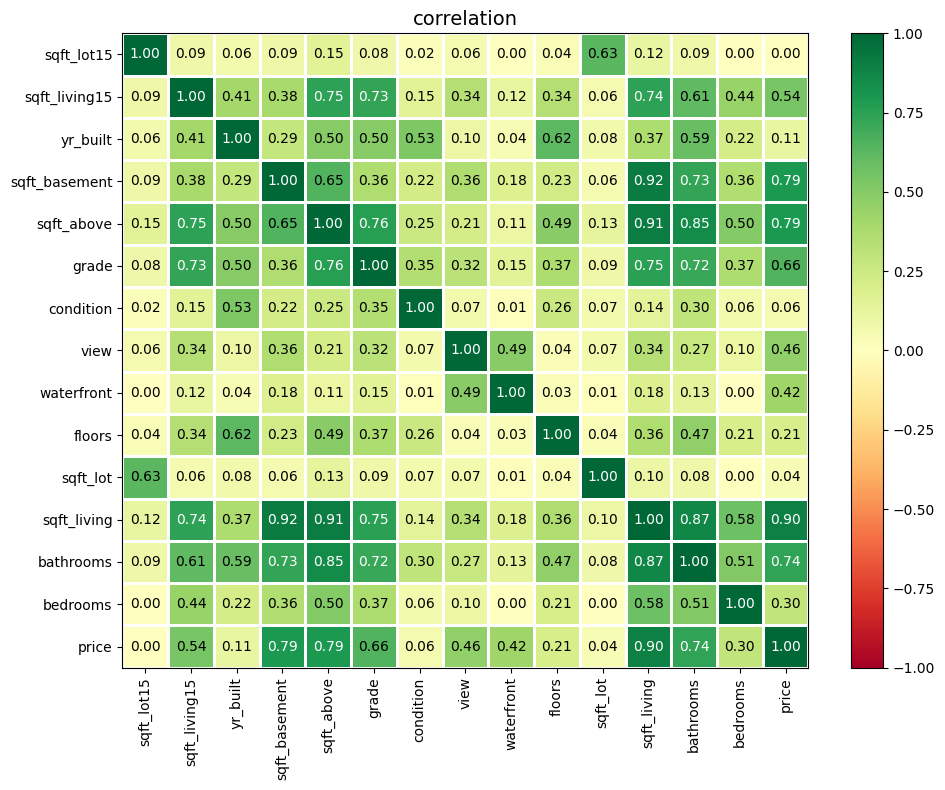

In [ ]:
corr_matrix = df.phik_matrix()
plot_correlation_matrix(corr_matrix.values, x_labels=corr_matrix.columns, y_labels=corr_matrix.index, figsize=(10, 8))

Видим, что между двумя признаками оказалась высокая корреляция.

Что тут можно сделать?
- Удалить один признак из такой пары:
- Попробовать применить **регуляризацию**.

Методы регуляризации работают путем добавления штрафных коэффициентов к исходной функции потерь модели таким образом, что высокие значения коэффициентов снижаются. А признаки с очень низкими значениями коэффициентов (после штрафования) могут быть вообще отброшены. Это помогает уменьшать сложность модели, а также **снижает риск переобучения** путём уменьшения сложности модели.

**Штраф** — это дополнительное неотрицательное слагаемое в выражении для функции потерь, которое специально повышает ошибку.  За счёт этого слагаемого метод оптимизации будет находить не истинный минимум функции потерь, а псевдоминимум.

Существует множество методов регуляризации, из которых мы обсудим три наиболее часто используемых, а именно: Rigde, Lasso и Elastic Net.




 Если мы используем регуляризацию, то масштабирование признаков становится ещё более важным. Регуляризация накладывает штрафы на величины коэффициентов, и если признаки не отмасштабированы, модель может неправильно оценивать их важность.



### L-1-регуляризация (Lasso)

In [ ]:
from sklearn.linear_model import Lasso

Такая регуляризация сводится к добавлению к функции потерь суммы модулей коэффициентов, умноженных на коэффициент регуляризации:
$$L1(w) = MSE + \lambda * \sum_{i=1}^{n} |w_i|$$

Здесь альфа является гиперпараметром, представляющим силу регуляризации. Высокое значение альфа налагает высокий штраф на сумму величин значений коэффициентов. Значение альфа может быть любым положительным значением вещественного числа. По умолчанию alpha=1. Когда альфа равна 0, это то же самое, что реализация стандартной множественной линейной регрессии.

Отличительной особенностью L1-регуляризации является то, что коэффициенты, которые соответствуют «ненужным», по мнению модели, факторам, обнуляются, то есть факторы просто не будут участвовать в предсказании. Это очень важно для сложных моделей, в обучении которых используются множество факторов. Тем самым мы уменьшим сложность модели, сократим её разброс и, как следствие, уменьшим переобучение.







Параметр alpha имеет очень важное значение: от его выбора зависит, как сильно мы будем штрафовать модель за переобучение. Важно найти значение, которое приносит наилучший эффект.

Давайте организуем процесс перебора параметров модели.

В цикле будем обучать модель линейной регрессии и L1-регуляризацией (Lasso), вычислять значения метрики  на тренировочной и валидационных выборках и заносить результаты в списки train_scores и cv_scores:

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.619e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent

alpha=    0.00 | R2 train=0.7511 | R2 test=0.7067 | нулевых коэф.: 0/119
alpha=  222.22 | R2 train=0.7509 | R2 test=0.7148 | нулевых коэф.: 21/119
alpha=  444.44 | R2 train=0.7504 | R2 test=0.7204 | нулевых коэф.: 26/119
alpha=  666.67 | R2 train=0.7498 | R2 test=0.7241 | нулевых коэф.: 33/119
alpha=  888.89 | R2 train=0.7491 | R2 test=0.7256 | нулевых коэф.: 41/119
alpha= 1111.11 | R2 train=0.7484 | R2 test=0.7269 | нулевых коэф.: 45/119
alpha= 1333.33 | R2 train=0.7477 | R2 test=0.7273 | нулевых коэф.: 50/119
alpha= 1555.56 | R2 train=0.7471 | R2 test=0.7273 | нулевых коэф.: 56/119
alpha= 1777.78 | R2 train=0.7465 | R2 test=0.7270 | нулевых коэф.: 58/119
alpha= 2000.00 | R2 train=0.7459 | R2 test=0.7265 | нулевых коэф.: 59/119


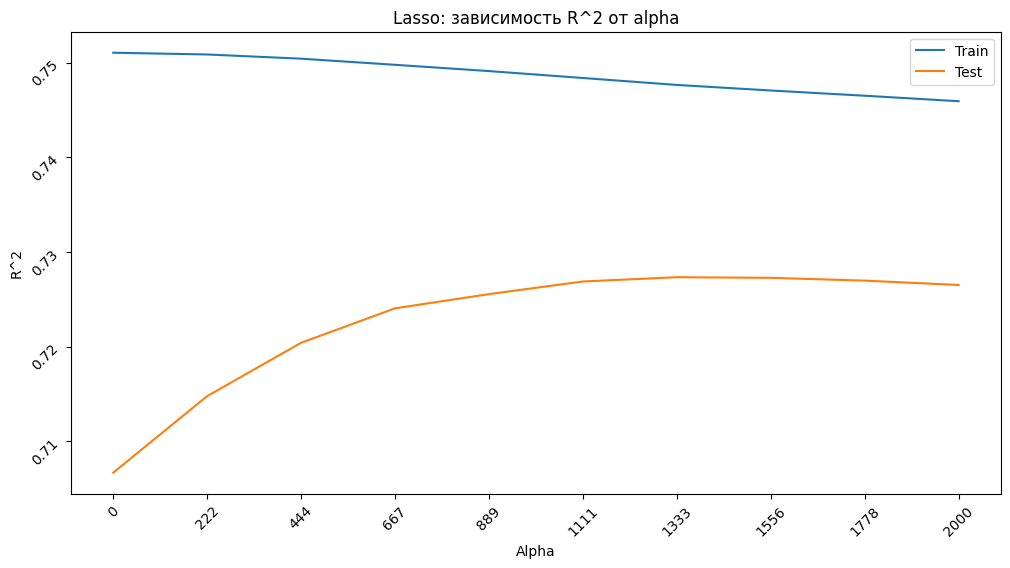


Лучший R^2 на тесте: 0.7273 при alpha = 1333.33
Соответствующий R^2 на трейне: 0.7477


In [ ]:
# Список из 10 значений alpha от 0 до 2000
alpha_list = np.linspace(0, 2000, 10)

train_scores = []
test_scores  = []

for alpha in alpha_list:
    lasso = Lasso(alpha=alpha, random_state=42)
    lasso.fit(X_train_poly, y_train)

    y_pred_train = lasso.predict(X_train_poly)
    y_pred_test  = lasso.predict(X_test_poly)

    train_scores.append(r2_score(y_train, y_pred_train))
    test_scores.append(r2_score(y_test,  y_pred_test))

    # сколько коэффициентов обнулилось — наглядно для L1
    n_zero = int(np.sum(np.isclose(lasso.coef_, 0)))
    print(f'alpha={alpha:8.2f} | R2 train={train_scores[-1]:.4f} | '
          f'R2 test={test_scores[-1]:.4f} | нулевых коэф.: {n_zero}/{len(lasso.coef_)}')

# График зависимости R2 от alpha
plt.figure(figsize=(12, 6))
plt.plot(alpha_list, train_scores, label='Train')
plt.plot(alpha_list, test_scores,  label='Test')
plt.xlabel('Alpha')
plt.ylabel('R^2')
plt.xticks(alpha_list)
plt.tick_params(rotation=45)
plt.legend()
plt.title('Lasso: зависимость R^2 от alpha')
plt.show()

# Выбираем лучший alpha по тестовой выборке
best_idx        = int(np.argmax(test_scores))
best_alpha_lasso = alpha_list[best_idx]
print(f'\nЛучший R^2 на тесте: {test_scores[best_idx]:.4f} при alpha = {best_alpha_lasso:.2f}')
print(f'Соответствующий R^2 на трейне: {train_scores[best_idx]:.4f}')



In [ ]:
# Коэффициенты финальной Lasso-модели
lasso_best = Lasso(alpha=best_alpha_lasso, random_state=42)
lasso_best.fit(X_train_poly, y_train)

poly_feature_names = poly.get_feature_names_out(input_features=X_train.columns)

coef_df = pd.DataFrame({
    'feature': poly_feature_names,
    'coef':    lasso_best.coef_
}).sort_values('coef', key=np.abs, ascending=False)

print(f'\nСвободный член: {lasso_best.intercept_:.4f}')
print(f'Ненулевых коэффициентов: {int(np.sum(~np.isclose(lasso_best.coef_, 0)))} '
      f'из {len(lasso_best.coef_)}')
coef_df.head(20)


Свободный член: 479134.0611
Ненулевых коэффициентов: 69 из 119


,feature,coef
8,grade,121456.845320
2,sqft_living,88773.176932
11,yr_built,-76865.940252
114,yr_built sqft_living15,-51275.929269
12,sqft_living15,43811.691133
47,sqft_living grade,24583.082078
113,yr_built^2,21616.623992
1,bathrooms,21318.294394
29,bathrooms sqft_living,21243.081805
96,condition sqft_living15,16498.576623


Обратите внимание: при достаточно большом alpha Lasso зануляет всё больше коэффициентов — признаки буквально «выключаются» из модели. Это и есть основной эффект L1-регуляризации.



Lasso (L1-регуляризацию) следует использовать, когда есть несколько характеристик с высокой предсказательной способностью, а остальные бесполезны. Она обнуляет бесполезные характеристики и оставляет только подмножество переменных.


### L2-регуляризация (Ridge)

Она же регуляризация Тихонова — добавление к функции потерь суммы квадратов коэффициентов, умноженных на коэффициент регуляризации:

$$L2(w) = MSE + \lambda * \sum_{i=1}^{n} w_i^2$$

Признаки опять же должны быть стандартизованы для одинаковых штрафов относительно друг друга!

Ridge технически проще вычисляется, чем Lasso.

alpha=    0.00 | R2 train=0.7493 | R2 test=0.7189
alpha=  222.22 | R2 train=0.7509 | R2 test=0.7125
alpha=  444.44 | R2 train=0.7505 | R2 test=0.7161
alpha=  666.67 | R2 train=0.7499 | R2 test=0.7183
alpha=  888.89 | R2 train=0.7492 | R2 test=0.7198
alpha= 1111.11 | R2 train=0.7484 | R2 test=0.7207
alpha= 1333.33 | R2 train=0.7475 | R2 test=0.7213
alpha= 1555.56 | R2 train=0.7467 | R2 test=0.7215
alpha= 1777.78 | R2 train=0.7458 | R2 test=0.7215
alpha= 2000.00 | R2 train=0.7448 | R2 test=0.7214


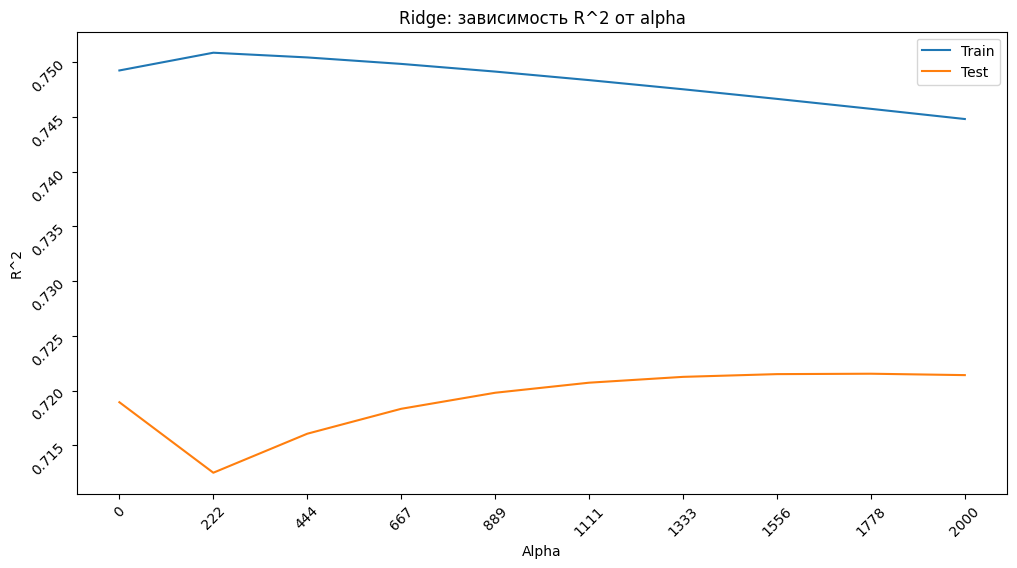

In [ ]:
from sklearn.linear_model import Ridge

alpha_list = np.linspace(0, 2000, 10)

train_scores = []
test_scores  = []

for alpha in alpha_list:
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge.fit(X_train_poly, y_train)

    y_pred_train = ridge.predict(X_train_poly)
    y_pred_test  = ridge.predict(X_test_poly)

    train_scores.append(r2_score(y_train, y_pred_train))
    test_scores.append(r2_score(y_test,  y_pred_test))

    print(f'alpha={alpha:8.2f} | R2 train={train_scores[-1]:.4f} | '
          f'R2 test={test_scores[-1]:.4f}')

plt.figure(figsize=(12, 6))
plt.plot(alpha_list, train_scores, label='Train')
plt.plot(alpha_list, test_scores,  label='Test')
plt.xlabel('Alpha')
plt.ylabel('R^2')
plt.xticks(alpha_list)
plt.tick_params(rotation=45)
plt.legend()
plt.title('Ridge: зависимость R^2 от alpha')
plt.show()



In [ ]:
best_idx       = int(np.argmax(test_scores))
best_alpha_ridge = alpha_list[best_idx]
print(f'\nЛучший R^2 на тесте: {test_scores[best_idx]:.4f} при alpha = {best_alpha_ridge:.2f}')
print(f'Соответствующий R^2 на трейне: {train_scores[best_idx]:.4f}')

# Коэффициенты финальной Ridge-модели
ridge_best = Ridge(alpha=best_alpha_ridge, random_state=42)
ridge_best.fit(X_train_poly, y_train)

print(f'\nСвободный член: {ridge_best.intercept_:.4f}')
print(f'Средний |coef|: {np.abs(ridge_best.coef_).mean():.4f}')
print(f'Максимальный |coef|: {np.abs(ridge_best.coef_).max():.4f}')


Лучший R^2 на тесте: 0.7215 при alpha = 1777.78
Соответствующий R^2 на трейне: 0.7458

Свободный член: 467624.6432
Средний |coef|: 7801.4596
Максимальный |coef|: 96142.2557


Отличие от Lasso: Ridge не зануляет коэффициенты, а «поджимает» их к нулю. Все признаки остаются в модели, но вклад каждого становится меньше. Это полезно, когда признаки коррелируют друг с другом.




Ridge-регрессия работает лучше в том случае, когда коэффициенты примерно одинакового размера, то есть все признаки влияют на целевую переменную примерно одинаково.

### Elastic Net регуляризация

Регуляризация Elastic Net сочетает в себе преимущества Lasso и Ridge-регуляризации в одной инструменте.

Функция потерь имеет два важных гиперпараметра: `alpha` и `l1_ratio`. Альфа в случае регуляризации Elastic Net — это константа, которая умножается на штрафы и для L1 (Lasso), и для L2 (Ridge). Гиперпараметр `l1_ratio` называется параметром смешивания таким образом, что `0 <= l1_ratio <= 1`.
Когда `l1_ratio` равен 1, это означает, что доля L1 (Lasso) равна 100%, а доля L2 (Ridge) равна 0%, то есть по факту просто делается Lasso-регуляризация. Аналогично, когда `l1_ratio` равно 0, это то же самое, что обычная Ridge-регуляризация.

Чтобы найти значения l1_ratio и alpha, при которых коэффициент детерминации ( R^2 ) максимален для тренировочной и тестовой выборок, мы сохраняем эти значения вместе с соответствующими ( R^2 ) в процессе перебора параметров.

In [ ]:
from sklearn.linear_model import ElasticNet

l1_ratio_list = np.linspace(0, 1, 10)
alpha_list    = np.linspace(0, 2000, 10)

best_train_score  = -np.inf
best_test_score   = -np.inf
best_train_params = (None, None)
best_test_params  = (None, None)

for l1_ratio in l1_ratio_list:
    for alpha in alpha_list:
        enet = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42)
        enet.fit(X_train_poly, y_train)

        train_mean = r2_score(y_train, enet.predict(X_train_poly))
        test_mean  = r2_score(y_test,  enet.predict(X_test_poly))

        print(f'alpha={alpha:8.2f} | l1_ratio={l1_ratio:.2f} | '
              f'train={train_mean:.4f} | test={test_mean:.4f}')

        if train_mean > best_train_score:
            best_train_score  = train_mean
            best_train_params = (alpha, l1_ratio)
        if test_mean > best_test_score:
            best_test_score  = test_mean
            best_test_params = (alpha, l1_ratio)

print(f'\nЛучший R2 на трейне: {best_train_score:.4f} '
      f'| alpha={best_train_params[0]:.2f}, l1_ratio={best_train_params[1]:.2f}')
print(f'Лучший R2 на тесте:  {best_test_score:.4f} '
      f'| alpha={best_test_params[0]:.2f}, l1_ratio={best_test_params[1]:.2f}')

# Финальная модель ElasticNet с лучшими параметрами по тесту
best_alpha_enet, best_l1_enet = best_test_params
enet_best = ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, random_state=42)
enet_best.fit(X_train_poly, y_train)

y_pred_enet = enet_best.predict(X_test_poly)
print(f'\nR2 финальной ElasticNet на тесте: {r2_score(y_test, y_pred_enet):.4f}')
print(f'Ненулевых коэффициентов: '
      f'{int(np.sum(~np.isclose(enet_best.coef_, 0)))} из {len(enet_best.coef_)}')

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.619e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent

alpha=    0.00 | l1_ratio=0.00 | train=0.7511 | test=0.7067


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.391e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


alpha=  222.22 | l1_ratio=0.00 | train=0.1857 | test=0.2106


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.864e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


alpha=  444.44 | l1_ratio=0.00 | train=0.1142 | test=0.1325


... (28 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.619e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent

alpha=    0.00 | l1_ratio=0.89 | train=0.7511 | test=0.7067
alpha=  222.22 | l1_ratio=0.89 | train=0.4626 | test=0.4627
alpha=  444.44 | l1_ratio=0.89 | train=0.3831 | test=0.3994
alpha=  666.67 | l1_ratio=0.89 | train=0.3298 | test=0.3530
alpha=  888.89 | l1_ratio=0.89 | train=0.2905 | test=0.3164
alpha= 1111.11 | l1_ratio=0.89 | train=0.2601 | test=0.2869
alpha= 1333.33 | l1_ratio=0.89 | train=0.2357 | test=0.2625
alpha= 1555.56 | l1_ratio=0.89 | train=0.2157 | test=0.2420
alpha= 1777.78 | l1_ratio=0.89 | train=0.1990 | test=0.2246
alpha= 2000.00 | l1_ratio=0.89 | train=0.1847 | test=0.2095


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.619e+14, tolerance: 2.104e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent

alpha=    0.00 | l1_ratio=1.00 | train=0.7511 | test=0.7067
alpha=  222.22 | l1_ratio=1.00 | train=0.7509 | test=0.7148
alpha=  444.44 | l1_ratio=1.00 | train=0.7504 | test=0.7204
alpha=  666.67 | l1_ratio=1.00 | train=0.7498 | test=0.7241
alpha=  888.89 | l1_ratio=1.00 | train=0.7491 | test=0.7256
alpha= 1111.11 | l1_ratio=1.00 | train=0.7484 | test=0.7269
alpha= 1333.33 | l1_ratio=1.00 | train=0.7477 | test=0.7273
alpha= 1555.56 | l1_ratio=1.00 | train=0.7471 | test=0.7273
alpha= 1777.78 | l1_ratio=1.00 | train=0.7465 | test=0.7270
alpha= 2000.00 | l1_ratio=1.00 | train=0.7459 | test=0.7265

Лучший R2 на трейне: 0.7511 | alpha=0.00, l1_ratio=0.00
Лучший R2 на тесте:  0.7273 | alpha=1333.33, l1_ratio=1.00

R2 финальной ElasticNet на тесте: 0.7273
Ненулевых коэффициентов: 69 из 119


Регуляризацию, конечно, можно применять только не только при генерации полиномиальных признаков.

*И на практике никогда не ясно, какой из методов регуляризации сработает лучше всего. Выход — пробовать разные метода и сравнивать результаты.*



# Регуляризация при классификации

Во избежание переобучения модели в функцию потерь логистической регрессии так же может быть добавлена регуляризация. В реализации логистической регрессии в sklearn она немного отличается от того, что вы видели для линейной регрессии.

При L1-регуляризации мы добавляем в функцию потерь L(w) штраф из суммы модулей параметров, а саму функцию logloss умножаем на коэффициент C:

$$L(w)=C \cdot \log \operatorname{loss}+\sum_{j=1}^{m}\left|w_{j}\right| \rightarrow \min_{w}$$

А при L2-регуляризации — штраф из суммы квадратов параметров:

$$L(w)=C \cdot \log \operatorname{loss}+\sum_{j=1}^{m}\left(w_{j}\right)^{2} \rightarrow \min _{w}$$

Значение коэффициента C — коэффициент, обратный коэффициенту регуляризации. Чем больше C, тем меньше «сила» регуляризации.

Все эти страшные формулы уже реализованы в классических библиотеках, таких как sklearn. Но нам важно понимать принцип того, что происходит «под капотом», чтобы верно интерпретировать результат и по возможности управлять им.



Важно: в sklearn LogisticRegression по умолчанию УЖЕ содержит
L2-регуляризацию с C=1.0. Чтобы получить модель «совсем без штрафа»,
нужно явно указать penalty=None (в старых версиях sklearn — 'none').

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

df = pd.read_csv(
    'https://raw.githubusercontent.com/obulygin/content/main/gym_churn/gym_churn.csv'
)
df.columns = df.columns.str.lower()

X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, stratify=y,
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Баланс классов в трейне: '
      f'{y_train.value_counts(normalize=True).round(3).to_dict()}')

X_train: (3000, 13), X_test: (1000, 13)
Баланс классов в трейне: {0: 0.735, 1: 0.265}


In [ ]:
# Общие гиперпараметры для всех запусков логистической регрессии
BASE = dict(max_iter=1000, random_state=42)


def evaluate(model, X_train, y_train, X_test, y_test, label):
    """Обучает модель и возвращает метрики на тесте одной строкой для таблицы."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return {
        'Модель':    label,
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
    }


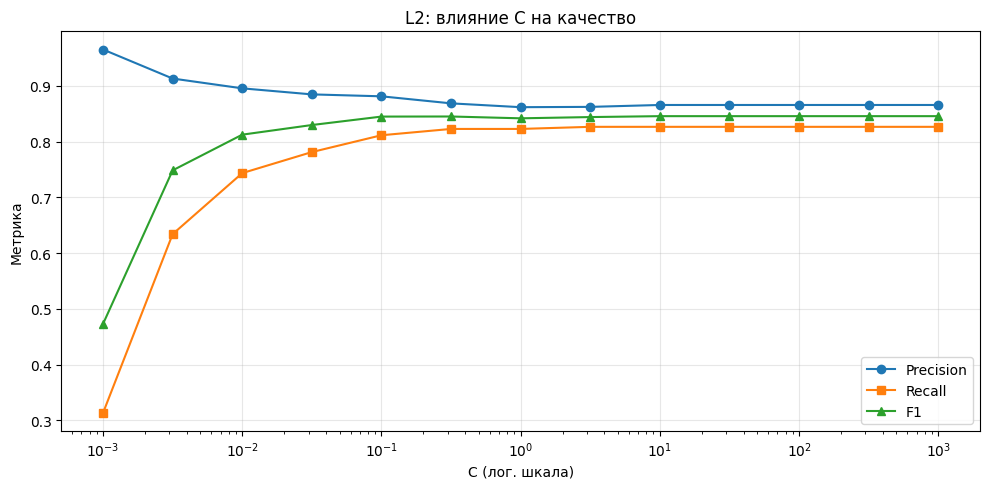

Лучшее C для L2 по F1: 10 (F1 = 0.8456)


In [ ]:
C_grid = np.logspace(-3, 3, 13)   # 0.001 … 1000

# --- 2.1. L2 ---
l2_rows = []
for C in C_grid:
    lr = LogisticRegression(penalty='l2', C=C, solver='lbfgs', **BASE)
    m = evaluate(lr, X_train, y_train, X_test, y_test, f'C={C:.3g}')
    m['C'] = C
    l2_rows.append(m)
df_l2 = pd.DataFrame(l2_rows)

fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(df_l2['C'], df_l2['Precision'], 'o-', label='Precision')
ax.semilogx(df_l2['C'], df_l2['Recall'],    's-', label='Recall')
ax.semilogx(df_l2['C'], df_l2['F1'],        '^-', label='F1')
ax.set_xlabel('C (лог. шкала)')
ax.set_ylabel('Метрика')
ax.set_title('L2: влияние C на качество')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

best_C_l2 = df_l2.loc[df_l2['F1'].idxmax(), 'C']
print(f'Лучшее C для L2 по F1: {best_C_l2:.3g} '
      f'(F1 = {df_l2["F1"].max():.4f})')

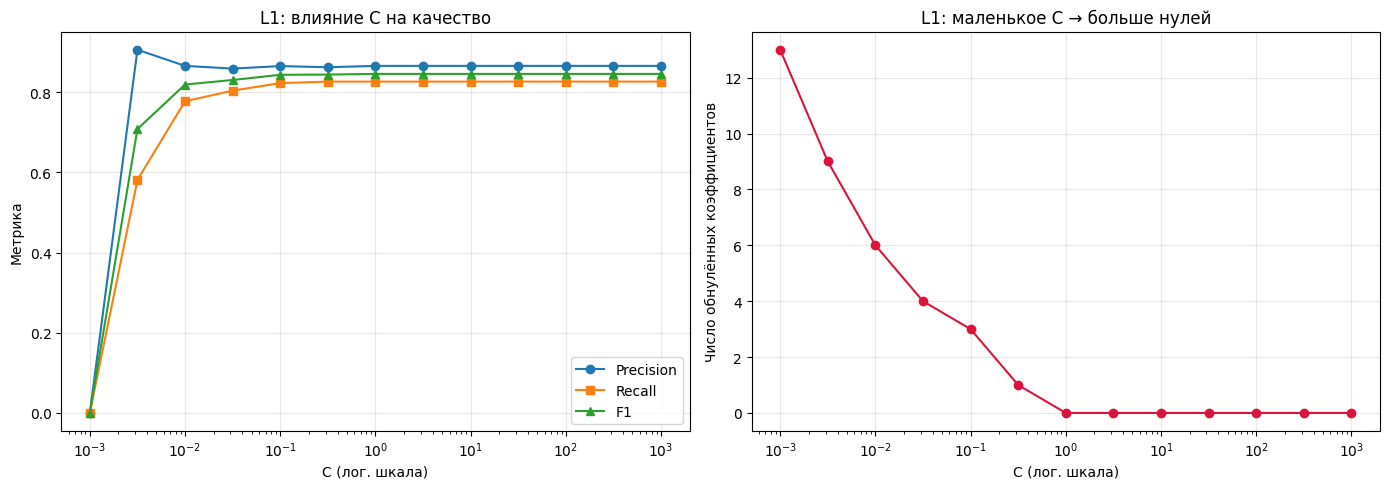

Лучшее C для L1 по F1: 1 (F1 = 0.8456, обнулено 0.0 из 13.0)


In [ ]:
l1_rows = []
for C in C_grid:
    lr = LogisticRegression(penalty='l1', C=C,
                            solver='liblinear', **BASE)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    l1_rows.append({
        'C':             C,
        'Precision':     precision_score(y_test, y_pred, zero_division=0),
        'Recall':        recall_score(y_test, y_pred, zero_division=0),
        'F1':            f1_score(y_test, y_pred, zero_division=0),
        'Нулевых коэф.': int(np.sum(np.abs(lr.coef_) < 1e-8)),
        'Всего коэф.':   lr.coef_.size,
    })
df_l1 = pd.DataFrame(l1_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.semilogx(df_l1['C'], df_l1['Precision'], 'o-', label='Precision')
ax1.semilogx(df_l1['C'], df_l1['Recall'],    's-', label='Recall')
ax1.semilogx(df_l1['C'], df_l1['F1'],        '^-', label='F1')
ax1.set_xlabel('C (лог. шкала)')
ax1.set_ylabel('Метрика')
ax1.set_title('L1: влияние C на качество')
ax1.grid(alpha=0.3)
ax1.legend()

ax2.semilogx(df_l1['C'], df_l1['Нулевых коэф.'], 'o-', color='crimson')
ax2.set_xlabel('C (лог. шкала)')
ax2.set_ylabel('Число обнулённых коэффициентов')
ax2.set_title('L1: маленькое C → больше нулей')
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_row_l1 = df_l1.loc[df_l1['F1'].idxmax()]
best_C_l1 = best_row_l1['C']
print(f'Лучшее C для L1 по F1: {best_C_l1:.3g} '
      f'(F1 = {best_row_l1["F1"]:.4f}, '
      f'обнулено {best_row_l1["Нулевых коэф."]} из '
      f'{best_row_l1["Всего коэф."]})')